# SWYNEX Task 2 - Exploratory Data Analysis

## Project Overview

This project was completed as part of the SWYNEX Technologies internship Task 2 - Exploratory Data Analysis.

The objective is to analyze the prepared Titanic dataset using statistical analysis and visualizations to identify important patterns, relationships, and insights that could influence machine learning models or business decisions.

## Dataset

Titanic Passenger Dataset

## Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("titanic_cleaned.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 891
Number of columns: 11


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Survived
0    549
1    342
Name: count, dtype: int64


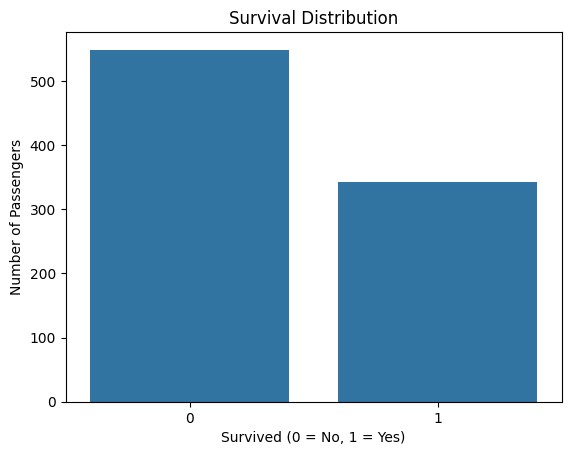

In [5]:
print(df["Survived"].value_counts())

sns.countplot(data=df, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


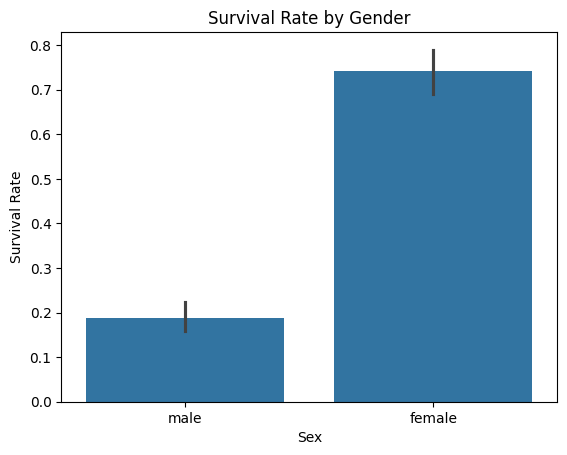

In [6]:
survival_gender = df.groupby("Sex")["Survived"].mean() * 100
print(survival_gender)

sns.barplot(data=df, x="Sex", y="Survived")
plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.show()

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


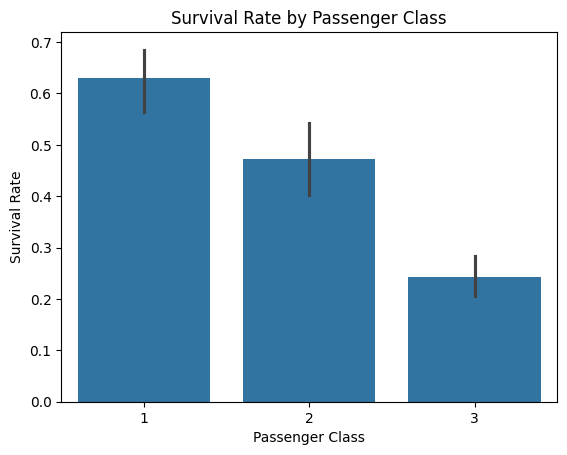

In [7]:
survival_class = df.groupby("Pclass")["Survived"].mean() * 100
print(survival_class)

sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

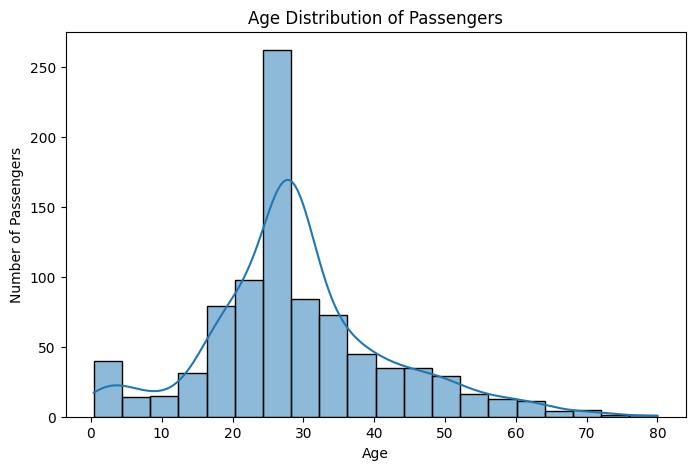

In [8]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

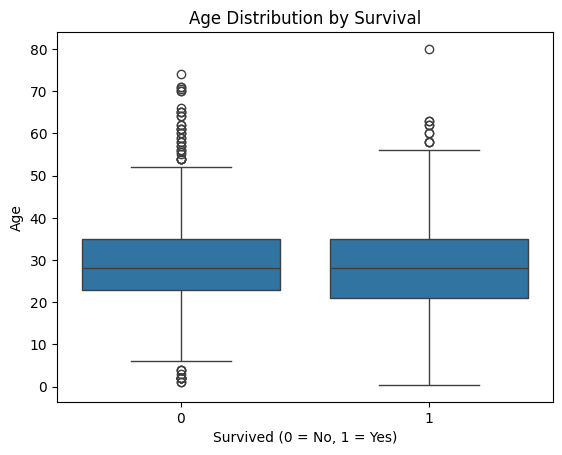

In [9]:
sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

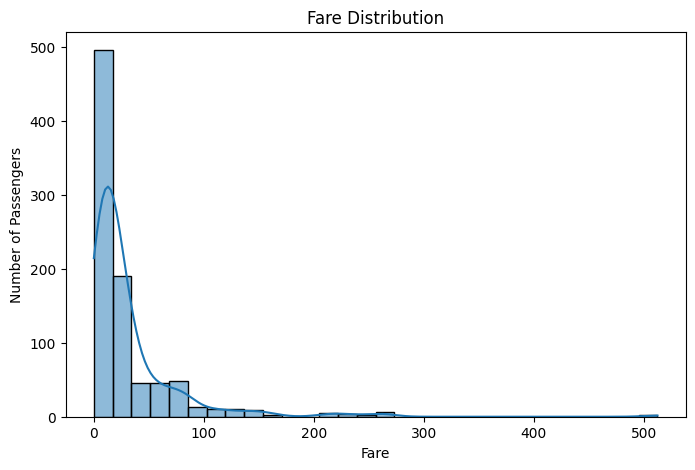

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(df["Fare"], bins=30, kde=True)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

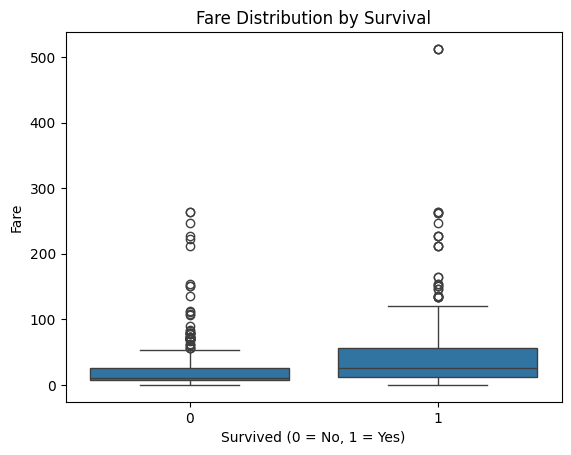

In [11]:
sns.boxplot(data=df, x="Survived", y="Fare")

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")

plt.show()

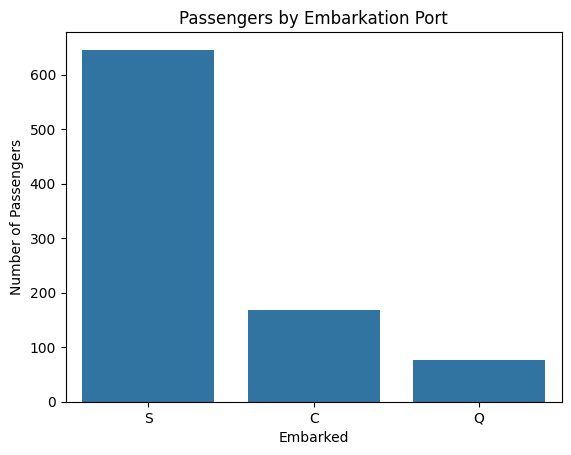

In [12]:
sns.countplot(data=df, x="Embarked")

plt.title("Passengers by Embarkation Port")
plt.xlabel("Embarked")
plt.ylabel("Number of Passengers")

plt.show()

In [13]:
embarked_survival = df.groupby("Embarked")["Survived"].mean() * 100
print(embarked_survival)

Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


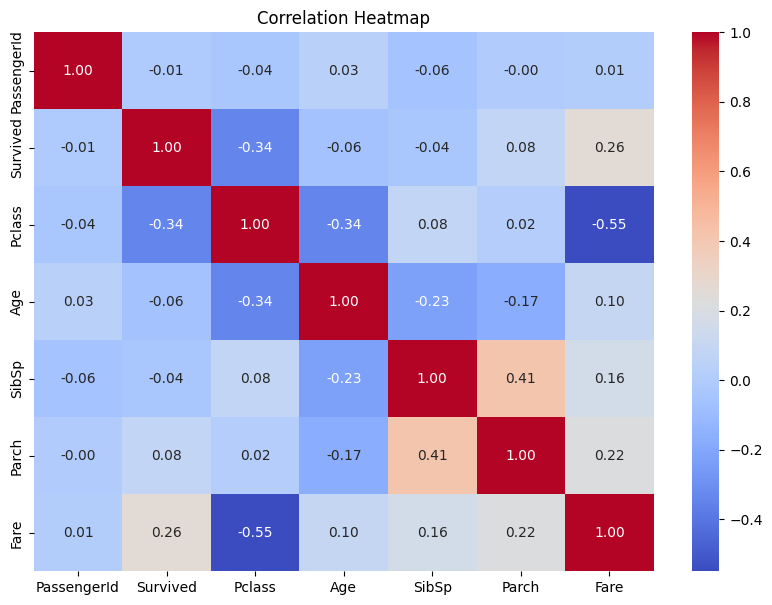

In [14]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
summary = pd.DataFrame({
    "Metric": [
        "Total Passengers",
        "Average Age",
        "Average Fare",
        "Survival Rate"
    ],
    "Value": [
        len(df),
        round(df["Age"].mean(), 2),
        round(df["Fare"].mean(), 2),
        round(df["Survived"].mean() * 100, 2)
    ]
})

summary

,Metric,Value
0,Total Passengers,891.00
1,Average Age,29.36
2,Average Fare,32.20
3,Survival Rate,38.38


# Key Findings and Insights

### Insight 1 - Gender and Survival
Survival rates differed significantly by gender. Female passengers had a much higher survival rate than male passengers. Therefore, gender can be an important feature for predicting survival.

### Insight 2 - Passenger Class and Survival
Passenger class had a strong relationship with survival. Higher-class passengers generally had better survival outcomes than lower-class passengers.

### Insight 3 - Age Distribution
Passengers belonged to a wide range of age groups. Age may provide useful information for predicting survival.

### Insight 4 - Age and Survival
The age distributions of survivors and non-survivors show differences. Therefore, Age can be considered as a useful feature for machine-learning models.

### Insight 5 - Fare Distribution
Fare values varied considerably among passengers. Higher fares may represent differences in passenger class and socioeconomic status.

### Insight 6 - Fare and Survival
Passengers paying higher fares generally showed better survival outcomes. Fare may therefore contain useful predictive information.

### Insight 7 - Correlation Between Variables
The correlation analysis shows relationships between numerical variables and can help identify useful features for future machine-learning models.

# Conclusion

Exploratory Data Analysis was performed on the cleaned Titanic dataset using Python, Pandas, Matplotlib, and Seaborn.

Statistical analysis and visualizations were used to understand the dataset and identify important patterns.

The analysis showed that factors such as gender, passenger class, age, and fare have meaningful relationships with passenger survival.

These findings can help in selecting relevant features and developing a machine-learning model for predicting passenger survival.

This task improved my understanding of data exploration, statistical analysis, visualization, and extracting meaningful insights from data.